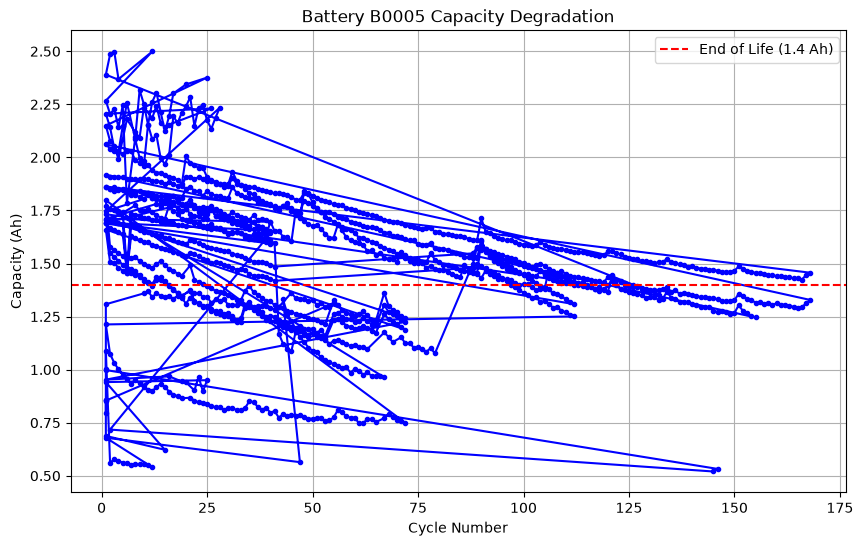

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#Loading the data
df = pd.read_csv('data/B0005.csv')

#Plotting the degradation curve
plt.figure(figsize=(10, 6))
plt.plot(df['cycle'], df['capacity'], marker='o', linestyle='-', color='b', markersize=3)
plt.axhline(y=1.4, color='r', linestyle='--', label='End of Life (1.4 Ah)')
plt.title('Battery B0005 Capacity Degradation')
plt.xlabel('Cycle Number')
plt.ylabel('Capacity (Ah)')
plt.legend()
plt.grid(True)
plt.show()

In [2]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. DATA LOADING & PREPARATION
# ==========================================
# Load the CSV file
df = pd.read_csv('data/B0005.csv')

# Defining Inputs (X) and Output (y)
X = df[['cycle', 'voltage', 'temperature']]
y = df['capacity']

# Spliting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling the data 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Converting Numpy arrays to PyTorch Tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# ==========================================
# 2. NEURAL NETWORK ARCHITECTURE
# ==========================================
class BatteryDegradationNN(nn.Module):
    def __init__(self):
        super(BatteryDegradationNN, self).__init__()
        self.layer1 = nn.Linear(3, 16) 
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(16, 8)
        self.output_layer = nn.Linear(8, 1)
        
    def forward(self, x):
        x = self.layer1(x)
        x = self.relu(x)
        x = self.layer2(x)
        x = self.relu(x)
        x = self.output_layer(x)
        return x

model = BatteryDegradationNN()

# ==========================================
# 3. TRAINING LOOP
# ==========================================
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 500
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    # Forward pass
    predictions = model(X_train_tensor)
    loss = criterion(predictions, y_train_tensor)
    
    # Backward pass and optimize
    loss.backward()
    optimizer.step()
    
    # Printing progress every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Training Loss: {loss.item():.4f}')

# ==========================================
# 4. EVALUATION
# ==========================================
model.eval()
with torch.no_grad():
    test_predictions = model(X_test_tensor)
    test_loss = criterion(test_predictions, y_test_tensor)
    print(f'\nFinal Test Mean Squared Error: {test_loss.item():.4f}')

Epoch [100/500], Training Loss: 0.0446
Epoch [200/500], Training Loss: 0.0373
Epoch [300/500], Training Loss: 0.0310
Epoch [400/500], Training Loss: 0.0271
Epoch [500/500], Training Loss: 0.0253

Final Test Mean Squared Error: 0.0463


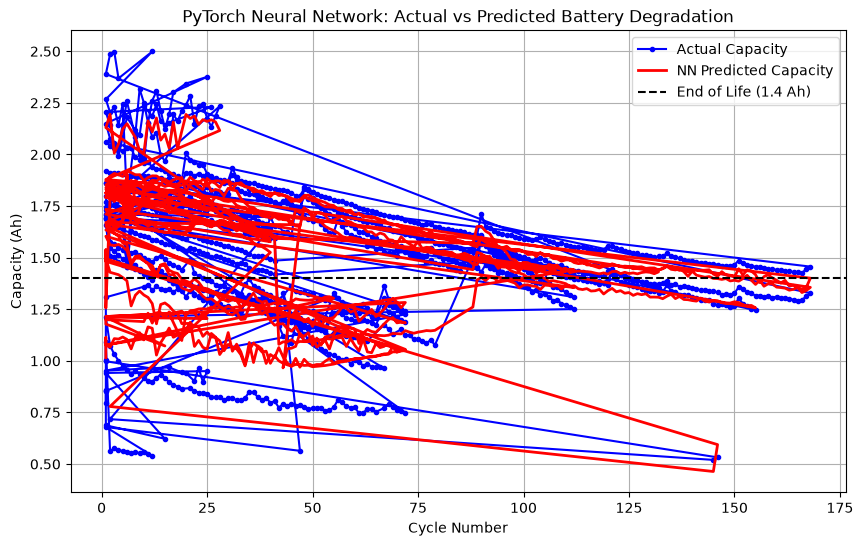

In [3]:
import matplotlib.pyplot as plt

# 1. Switch to evaluation mode
model.eval()

# 2. Prepare the entire dataset to see the full curve
with torch.no_grad():
    X_full_scaled = scaler.transform(X) # Scale all 168 cycles
    X_full_tensor = torch.tensor(X_full_scaled, dtype=torch.float32)
    
    # Get the model's predictions and convert them back to a Numpy array for plotting
    all_predictions = model(X_full_tensor).numpy()

# 3. Plot Actual vs Predicted
plt.figure(figsize=(10, 6))
plt.plot(df['cycle'], df['capacity'], label='Actual Capacity', color='blue', marker='o', markersize=3)
plt.plot(df['cycle'], all_predictions, label='NN Predicted Capacity', color='red', linestyle='-', linewidth=2)
plt.axhline(y=1.4, color='black', linestyle='--', label='End of Life (1.4 Ah)')

plt.title('PyTorch Neural Network: Actual vs Predicted Battery Degradation')
plt.xlabel('Cycle Number')
plt.ylabel('Capacity (Ah)')
plt.legend()
plt.grid(True)
plt.show()

In [4]:
import joblib

# 1. Save the PyTorch model weights
torch.save(model.state_dict(), 'src/battery_degradation_weights.pth')

# 2. Save the Scaler 

joblib.dump(scaler, 'src/feature_scaler.pkl')



['src/feature_scaler.pkl']